# 7a. XRO validation against observations

First of four XRO notebooks (run in order; each also runs on its own from the shared caches):

| Notebook | Question |
| --- | --- |
| **7a_xro_validation** | Is XRO, as configured here, a trustworthy observational benchmark? |
| 7b_xro_events | What does XRO predict for the 2015/16 and 2026/27 El Niños, and from which initial states? |
| 7c_e3sm_xro_state | Where and when do the E3SM hindcasts depart from observations and from XRO? |
| 7d_e3sm_recharge | Do E3SM and XRO differ in recharge-discharge dynamics or in the initial recharge? |

**XRO** (extended nonlinear recharge oscillator; Zhao et al. 2024, *Nature*,
doi:10.1038/s41586-024-07534-6) is fitted to a ten-variable observed state vector: ENSO
[Niño3.4 SST *T*, recharge *h*] plus eight other climate-mode SST indices (NPMM, SPMM, IOB, IOD,
SIOD, TNA, ATL3, SASD; boxes in `util/xro_case.py`). The configuration is the control model of the
paper (annual and semi-annual cycle, quadratic IOD term, *T*² and *Th* terms in the *T* equation),
set once in `xc.XRO_SETUP` for all four notebooks.

**Data.** HadISST 1.1 SST and EN4.2.2 0-700 m heat content, anomalies from their own 1981-2010
monthly climatology. *h* is the 5°S-5°N, 120°E-80°W mean OHC700 (GJ m⁻²), an equatorial Pacific
**OHC700 recharge proxy**, not the 20 °C-isotherm warm-water volume (WWV) of the paper: the hindcasts
save no subsurface temperature. XRO is fitted to detrended anomalies (linear trend for SST, quadratic
for *h*, fitted over the training years only); the trend is added back to forecasts.

**Checks in this notebook (no E3SM data):**

1. Observed state vector and training-period trends, linear vs quadratic for *h*.
2. Fitted recharge-oscillator parameters (growth rate, period) for the two training periods.
3. Intrinsic behaviour: long stochastic simulations against observed seasonal synchronization,
   *h*-leads-*T* lag correlation and persistence.
4. Out-of-sample skill: XRO refitted every year Y on 1981..Y-1 and run from every month of Y
   (1995-2025), against anomaly persistence; linear vs quadratic *h* detrending.
5. Skill by initial month (the months before the Feb/May/Aug/Nov hindcast starts).
6. Amplitude of the DJF peak: does XRO underpredict strong El Niños?
7. Calibration of the stochastic (red-noise) ensemble: spread vs error and 5-95% coverage.
8. Cross-validated spread calibration (inflation factors from already-verified forecasts).
9. Coverage vs CRPS calibration objective with bootstrap intervals; DJF-specific factors.
10. Executable audit of the out-of-sample procedure.

**Lead convention.** In this notebook XRO lead 0 is the initial month (observed); lead *L* verifies
*L* months later. XRO started from the month before a hindcast start has lead 1 = hindcast lead 0.

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from IPython.display import display

from util import rtenso_case as rc
from util import xro_case as xc
from util import pubfig as pf

pf.use_style()

### Run controls

In [2]:
NOTEBOOK = "7a_xro_validation"   # outputs: rc.OUTPUT_ROOT/7a_xro_validation/{figures,data}/
# "auto": reuse valid caches, rebuild stale ones; "rebuild": recompute (e.g. after new observations); "require": fail if missing
derivation_mode = "auto"

# Out-of-sample hindcasts: for each year in VALID["years"], fit on train_start..year-1 and start from every month of year
VALID = xc.VALIDATION   # shared with 7b/7c, which apply the calibration derived here
# Detrending options compared; the first is the control (must match xc.XRO_SETUP["detrend_order"])
TREND_OPTIONS = {"quadratic h": {"default": 1, "WWV": 2}, "linear h": {"default": 1, "WWV": 1}}
CONTROL = next(iter(TREND_OPTIONS))
assert TREND_OPTIONS[CONTROL] == xc.XRO_SETUP["detrend_order"], "first TREND_OPTIONS entry must be the control"
# Stochastic simulations for the intrinsic-behaviour checks
SIM = {"nyear": 100, "ncopy": 50, "seed": 2000}
# Initial months of XRO for the hindcast starts (start month - 1)
START_ICS = {init: xc.add_months(2000, init, -1)[1] for init in (2, 5, 8, 11)}
SKILL_VARS = ["Nino34", "WWV"]
STRONG = 1.5   # observed DJF Niño3.4 (°C) marking a strong El Niño

COLORS = {"XRO": xc.XRO_STYLE["color"], "XRO linear h": "#c77dff", "Persistence": "0.45", "Observed": "k"}
OUTDIR = rc.output_dir(NOTEBOOK, "data")
print("figures ->", rc.figure_dir(NOTEBOOK))

figures -> /global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7a_xro_validation/figures


## 1. Observed state vector and training-period trends

The trend is fitted over each event's training period (1981-2014 for 2015/16, 1981-2025 for
2026/27) and extrapolated. For *h* the control quadratic trend is compared with a linear one: a
quadratic fitted to a short record can bend strongly at its end, which then feeds every forecast.

In [3]:
X = xc.obs_state(mode=derivation_mode)
for var in SKILL_VARS:
    y, m = xc.last_observed(X, var)
    print(f"{xc.short(var)}: {X['time'].values[0].year}-{X['time'].values[0].month:02d} to {y}-{m:02d}")

TRAIN_PERIODS = sorted({event["train"] for event in xc.EVENTS.values()})
FITS = {(train, name): xc.fit_xro(X, train, orders=orders) for train in TRAIN_PERIODS for name, orders in TREND_OPTIONS.items()}

Niño3.4: 1981-01 to 2026-09
h (OHC700): 1981-01 to 2026-08


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7a_xro_validation/figures/fig_xro_obs_state_trends.pdf


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7a_xro_validation/figures/fig_xro_obs_state_trends.png


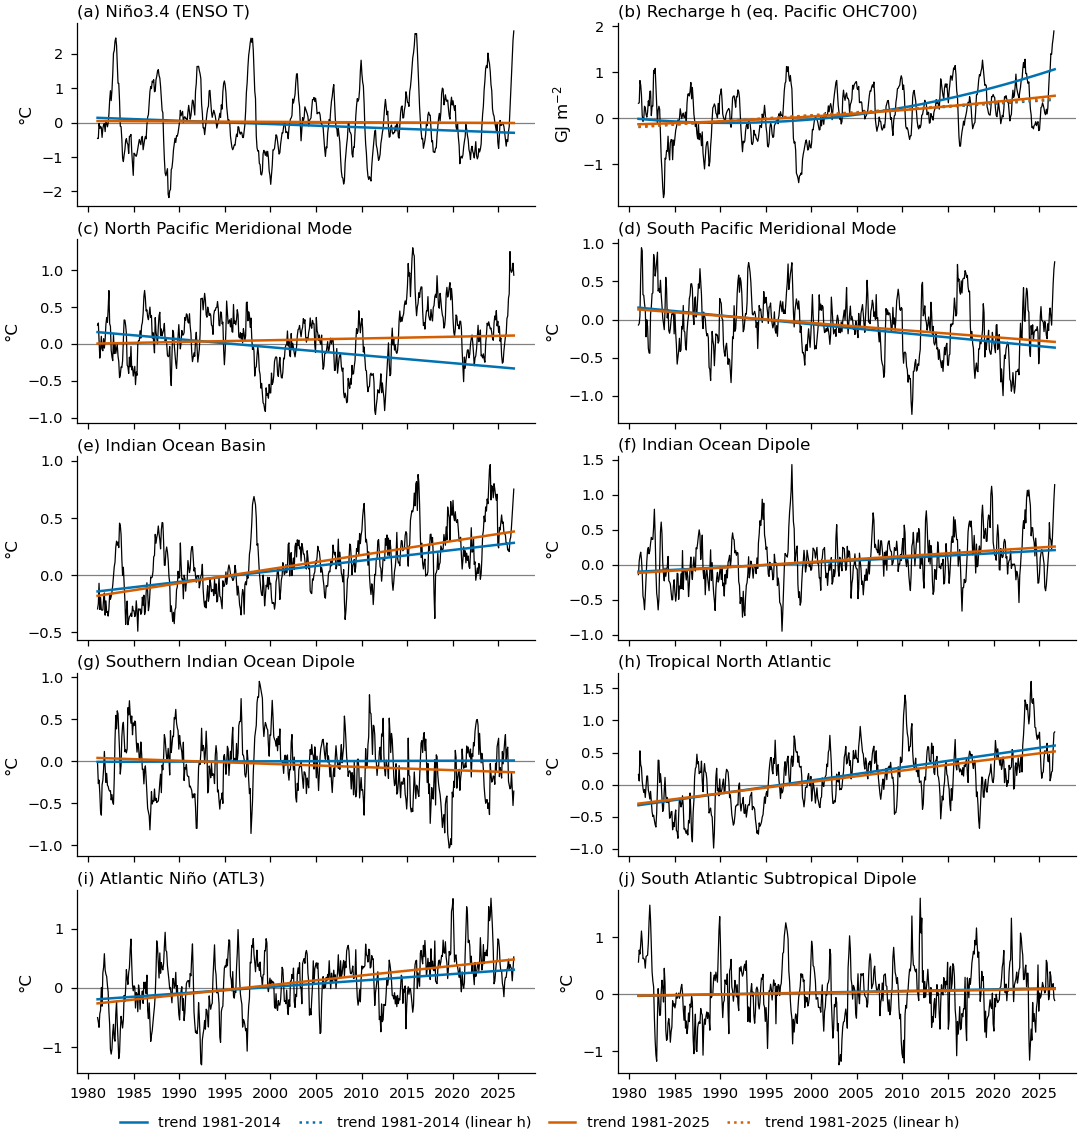

In [4]:
def plot_obs_state():
    fig, axes = plt.subplots(5, 2, figsize=(pf.WIDTH["double"], 7.6), sharex=True)
    t = pd.to_datetime([f"{d.year}-{d.month:02d}-15" for d in X["time"].values])
    train_colors = dict(zip(TRAIN_PERIODS, ["#0072b2", "#d55e00"]))
    for k, (ax, var) in enumerate(zip(axes.flat, xc.XRO_VARS)):
        ax.plot(t, X[var], color="k", lw=0.6)
        for train in TRAIN_PERIODS:
            for name in TREND_OPTIONS:
                if var != "WWV" and name != CONTROL:
                    continue
                tr = xc.trend_values(FITS[(train, name)]["trend"], X["time"].values)[var]
                ax.plot(t, tr, color=train_colors[train], lw=1.2, ls="-" if name == CONTROL else ":",
                        label=f"trend {train[0]}-{train[1]}" + ("" if name == CONTROL else f" ({name})"))
        pf.zero_line(ax)
        pf.panel_label(ax, k, xc.LABELS[var])
        ax.set_ylabel(xc.UNITS[var])
    handles, labels = axes.flat[1].get_legend_handles_labels()
    pf.legend_below(fig, handles, labels, ncol=4)
    return fig


fig = plot_obs_state()
pf.save(fig, NOTEBOOK, "xro", "obs_state_trends")
plt.show()

## 2. Fitted recharge-oscillator parameters

XRO's ENSO block is dT/dt = R T + F₁ h, dh/dt = −F₂ T − ε h (per year), with seasonally varying
coefficients. Its eigenvalues give the growth rate (R − ε)/2 and the period
2π / √(F₁F₂ − ((R + ε)/2)²). F₁ and F₂ carry the units of *h*, so with OHC700 instead of WWV they
differ from the paper's values; their product, and therefore the period, does not. A damped
(negative growth rate) oscillator with a period of a few years is the expected recharge-oscillator
regime; large differences between the two training periods would mean the benchmark is not stable.

,R (1/yr),F1,F2,ε (1/yr),growth (1/yr),period (yr)
1981-2014,-1.03,2.71,0.57,1.39,-1.21,5.11
1981-2025,-1.12,2.66,0.57,1.11,-1.12,5.11


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7a_xro_validation/figures/fig_xro_ro_parameters.pdf


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7a_xro_validation/figures/fig_xro_ro_parameters.png


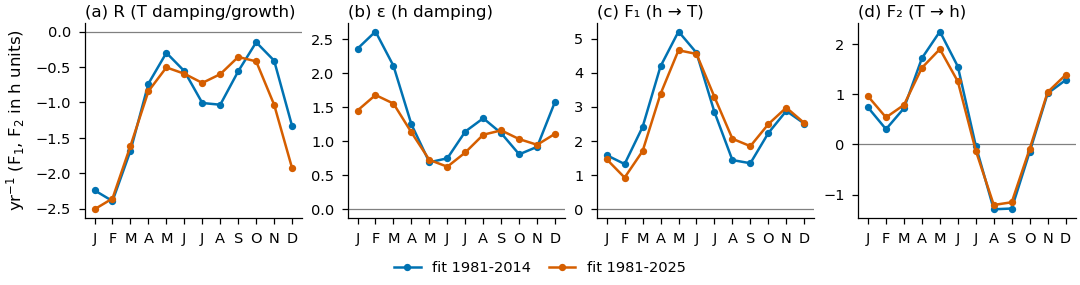

In [5]:
ro = {train: xc.ro_parameters(FITS[(train, CONTROL)]) for train in TRAIN_PERIODS}
ro_table = pd.DataFrame({f"{a}-{b}": ann for (a, b), (_, ann) in ro.items()}).T
ro_table.columns = ["R (1/yr)", "F1", "F2", "ε (1/yr)", "growth (1/yr)", "period (yr)"]
ro_table.round(3).to_csv(OUTDIR / "XRO_RO_parameters_annual_mean.csv")
display(ro_table.round(2))

fig, axes = plt.subplots(1, 4, figsize=(pf.WIDTH["double"], 1.9))
month_letters = list("JFMAMJJASOND")
for train, color in zip(TRAIN_PERIODS, ["#0072b2", "#d55e00"]):
    p, _ = ro[train]
    for k, (ax, key, title) in enumerate(zip(axes, ["R", "epsilon", "F1", "F2"],
                                              ["R (T damping/growth)", "ε (h damping)", "F₁ (h → T)", "F₂ (T → h)"])):
        ax.plot(range(1, 13), p[key], color=color, marker="o", ms=2.5, label=f"fit {train[0]}-{train[1]}")
        pf.panel_label(ax, k, title)
for ax in axes:
    ax.set_xticks(range(1, 13), month_letters)
    pf.zero_line(ax)
axes[0].set_ylabel("yr$^{-1}$ (F$_1$, F$_2$ in h units)")
pf.legend_below(fig, ax=axes[0], ncol=2)
pf.save(fig, NOTEBOOK, "xro", "ro_parameters")
plt.show()

## 3. Intrinsic behaviour: stochastic simulations vs observations

`SIM["ncopy"]` simulations of `SIM["nyear"]` years from each fit, compared with the detrended
observations of the same training years: (a) Niño3.4 standard deviation by calendar month (ENSO
phase-locking to boreal winter), (b) lag correlation of *h*(t) with *T*(t + lag) (recharge leads ENSO
by several months, positive lags), (c) Niño3.4 autocorrelation (persistence and the spring barrier
in the annual mean). Shading is the 5-95% range across simulations; the skewness table checks the
El Niño-La Niña asymmetry that the *T*² and *Th* terms should produce.

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7a_xro_validation/figures/fig_xro_intrinsic_behaviour.pdf


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7a_xro_validation/figures/fig_xro_intrinsic_behaviour.png


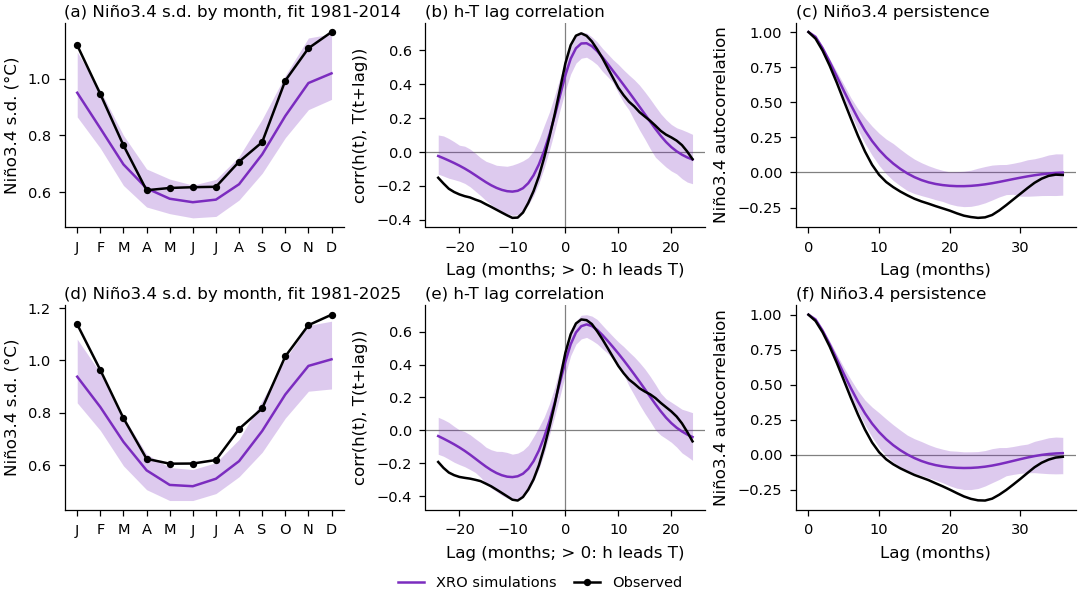

,observed,XRO mean,XRO 5%,XRO 95%
fit,,,,
1981-2014,0.30,0.28,-0.04,0.68
1981-2025,0.48,0.27,-0.06,0.63


In [6]:
def lag_corr(a, b, lags):
    """corr(a(t), b(t + lag)) for each lag."""
    a, b = np.asarray(a, float), np.asarray(b, float)
    out = []
    for L in lags:
        x, y = (a[: len(a) - L], b[L:]) if L >= 0 else (a[-L:], b[: len(b) + L])
        ok = np.isfinite(x) & np.isfinite(y)
        out.append(np.corrcoef(x[ok], y[ok])[0, 1])
    return np.array(out)


def skewness(x):
    x = np.asarray(x, float)
    x = x[np.isfinite(x)] - np.nanmean(x)
    return float(np.mean(x ** 3) / np.mean(x ** 2) ** 1.5)


LAGS = np.arange(-24, 25)
ACF_LAGS = np.arange(0, 37)
fig, axes = plt.subplots(len(TRAIN_PERIODS), 3, figsize=(pf.WIDTH["double"], 2.0 * len(TRAIN_PERIODS)))
skew_rows = []
for r, train in enumerate(TRAIN_PERIODS):
    xf = FITS[(train, CONTROL)]
    obs = xf["X_dt"].sel(time=slice(f"{train[0]}-01", f"{train[1]}-12"))
    sim = xc.simulate(xf, **SIM)
    ax = axes[r, 0]
    sd_sim = sim["Nino34"].groupby("time.month").std("time")
    ax.fill_between(range(1, 13), sd_sim.quantile(0.05, "member"), sd_sim.quantile(0.95, "member"),
                    color=COLORS["XRO"], alpha=0.25, lw=0)
    ax.plot(range(1, 13), sd_sim.mean("member"), color=COLORS["XRO"], label="XRO simulations")
    ax.plot(range(1, 13), obs["Nino34"].groupby("time.month").std("time"), color="k", marker="o", ms=2.5, label="Observed")
    ax.set_xticks(range(1, 13), month_letters)
    ax.set_ylabel("Niño3.4 s.d. (°C)")
    pf.panel_label(ax, 3 * r, f"Niño3.4 s.d. by month, fit {train[0]}-{train[1]}")
    ax = axes[r, 1]
    lc = np.array([lag_corr(sim["WWV"].sel(member=m), sim["Nino34"].sel(member=m), LAGS) for m in sim["member"].values])
    ax.fill_between(LAGS, np.percentile(lc, 5, 0), np.percentile(lc, 95, 0), color=COLORS["XRO"], alpha=0.25, lw=0)
    ax.plot(LAGS, lc.mean(0), color=COLORS["XRO"])
    ax.plot(LAGS, lag_corr(obs["WWV"], obs["Nino34"], LAGS), color="k")
    pf.zero_line(ax)
    pf.zero_line(ax, axis="x")
    ax.set_xlabel("Lag (months; > 0: h leads T)")
    ax.set_ylabel("corr(h(t), T(t+lag))")
    pf.panel_label(ax, 3 * r + 1, "h-T lag correlation")
    ax = axes[r, 2]
    acf = np.array([lag_corr(sim["Nino34"].sel(member=m), sim["Nino34"].sel(member=m), ACF_LAGS) for m in sim["member"].values])
    ax.fill_between(ACF_LAGS, np.percentile(acf, 5, 0), np.percentile(acf, 95, 0), color=COLORS["XRO"], alpha=0.25, lw=0)
    ax.plot(ACF_LAGS, acf.mean(0), color=COLORS["XRO"])
    ax.plot(ACF_LAGS, lag_corr(obs["Nino34"], obs["Nino34"], ACF_LAGS), color="k")
    pf.zero_line(ax)
    ax.set_xlabel("Lag (months)")
    ax.set_ylabel("Niño3.4 autocorrelation")
    pf.panel_label(ax, 3 * r + 2, "Niño3.4 persistence")
    sk = np.array([skewness(sim["Nino34"].sel(member=m)) for m in sim["member"].values])
    skew_rows.append({"fit": f"{train[0]}-{train[1]}", "observed": round(skewness(obs["Nino34"]), 2),
                      "XRO mean": round(float(sk.mean()), 2), "XRO 5%": round(float(np.percentile(sk, 5)), 2),
                      "XRO 95%": round(float(np.percentile(sk, 95)), 2)})
pf.legend_below(fig, ax=axes[0, 0], ncol=2)
pf.save(fig, NOTEBOOK, "xro", "intrinsic_behaviour")
plt.show()
skew = pd.DataFrame(skew_rows).set_index("fit")
skew.to_csv(OUTDIR / "XRO_Nino34_skewness.csv")
display(skew)

## 4. Out-of-sample forecast skill

Each year Y in `VALID["years"]` is forecast by an XRO detrended and fitted on 1981..Y-1 only, from
every observed month of Y, so no forecast has seen its target. Forecasts are verified as full
(not detrended) anomalies, the quantity compared with E3SM later, against anomaly persistence.
Monthly values, no running mean; the verification sample shrinks slightly at long leads near the
end of the record. Cached under `S2D_DIAG_ROOT/observations/xro/`.

In [7]:
%%time
HIND = {}
for name, orders in TREND_OPTIONS.items():
    HIND[name] = xc.rolling_hindcasts(X, VALID["years"], VALID["train_start"], VALID["n_month"], orders=orders,
                                      ncopy=VALID["ncopy"] if name == CONTROL else 0, seed=VALID["seed"],
                                      mode=derivation_mode)
det, stoch = HIND[CONTROL]
OBS_GRID = xc.target_obs(det, X)
print(f"{det.sizes['init']} initial months, {pd.Timestamp(det['init'].values[0]):%Y-%m} to {pd.Timestamp(det['init'].values[-1]):%Y-%m}")

def skill_table(fc, obs):
    return {var: xc.skill(fc[var], obs[var]) for var in SKILL_VARS}


SKILL = {name: skill_table(HIND[name][0], xc.target_obs(HIND[name][0], X)) for name in TREND_OPTIONS}
SKILL["Persistence"] = skill_table(xc.persistence(det, OBS_GRID), OBS_GRID)
obs_sd = {var: float(X[var].sel(time=slice(f"{VALID['years'][0]}-01", None)).std()) for var in SKILL_VARS}

372 initial months, 1995-01 to 2025-12


CPU times: user 57.3 s, sys: 1.05 s, total: 58.3 s
Wall time: 59.1 s


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7a_xro_validation/figures/fig_xro_oos_skill_by_lead.pdf


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7a_xro_validation/figures/fig_xro_oos_skill_by_lead.png


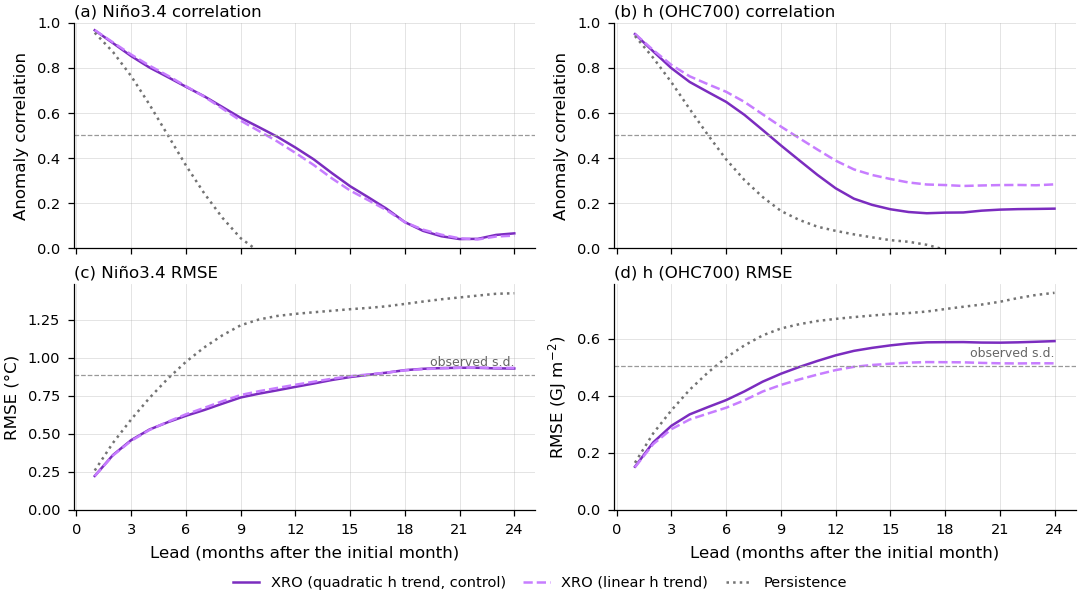

lead                      1     3     6     9     12    18
variable   forecast                                       
Niño3.4    Persistence  0.96  0.76  0.37  0.05 -0.07 -0.17
           linear h     0.97  0.86  0.72  0.57  0.42  0.12
           quadratic h  0.97  0.85  0.72  0.58  0.45  0.12
h (OHC700) Persistence  0.94  0.74  0.39  0.17  0.08 -0.01
           linear h     0.95  0.81  0.69  0.54  0.39  0.28
           quadratic h  0.95  0.80  0.65  0.46  0.27  0.16

In [8]:
STYLES = {CONTROL: {"color": COLORS["XRO"], "label": f"XRO ({CONTROL} trend, control)"},
          "linear h": {"color": COLORS["XRO linear h"], "ls": "--", "label": "XRO (linear h trend)"},
          "Persistence": {"color": COLORS["Persistence"], "ls": ":", "label": "Persistence"}}
fig, axes = plt.subplots(2, 2, figsize=(pf.WIDTH["double"], 4.0), sharex=True)
leads = det["lead"].values[1:]
for c, var in enumerate(SKILL_VARS):
    for name, st in STYLES.items():
        sk = SKILL[name][var].isel(lead=slice(1, None))
        axes[0, c].plot(leads, sk["acc"], **st)
        axes[1, c].plot(leads, sk["rmse"], **st)
    axes[0, c].axhline(0.5, color="0.6", lw=0.6, ls="--")
    axes[0, c].set_ylim(0, 1)
    axes[1, c].axhline(obs_sd[var], color="0.6", lw=0.6, ls="--")
    axes[1, c].annotate("observed s.d.", (leads[-1], obs_sd[var]), xytext=(0, 3), textcoords="offset points",
                         va="bottom", ha="right", fontsize=6, color="0.4")
    axes[1, c].set_ylim(0, None)
    axes[0, c].set_ylabel("Anomaly correlation")
    axes[1, c].set_ylabel(f"RMSE ({xc.UNITS[var]})")
    axes[1, c].set_xlabel("Lead (months after the initial month)")
    pf.panel_label(axes[0, c], c, f"{xc.short(var)} correlation")
    pf.panel_label(axes[1, c], 2 + c, f"{xc.short(var)} RMSE")
for ax in axes.flat:
    ax.set_xticks(range(0, VALID["n_month"] + 1, 3))
    ax.grid(True)
pf.legend_below(fig, ax=axes[0, 0], ncol=3)
pf.save(fig, NOTEBOOK, "xro", "oos_skill_by_lead")
plt.show()

rows = []
for name in STYLES:
    for var in SKILL_VARS:
        for L in (1, 3, 6, 9, 12, 18):
            sk = SKILL[name][var].sel(lead=L)
            rows.append({"forecast": name, "variable": xc.short(var), "lead": L, "acc": round(float(sk["acc"]), 2),
                         "rmse": round(float(sk["rmse"]), 2), "n": int(sk["n"])})
skill_summary = pd.DataFrame(rows)
skill_summary.to_csv(OUTDIR / "XRO_oos_skill_summary.csv", index=False)
display(skill_summary.pivot_table(index=["variable", "forecast"], columns="lead", values="acc"))

## 5. Skill by initial month

Correlation skill of Niño3.4 and *h* for the four initial months used for the hindcast starts
(Jan, Apr, Jul, Oct → Feb, May, Aug, Nov starts), against target lead. Low skill through boreal
spring from the Jan initial month is the spring predictability barrier; this is the context for the
Feb-start comparisons with E3SM.

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7a_xro_validation/figures/fig_xro_oos_skill_by_initial_month.pdf


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7a_xro_validation/figures/fig_xro_oos_skill_by_initial_month.png


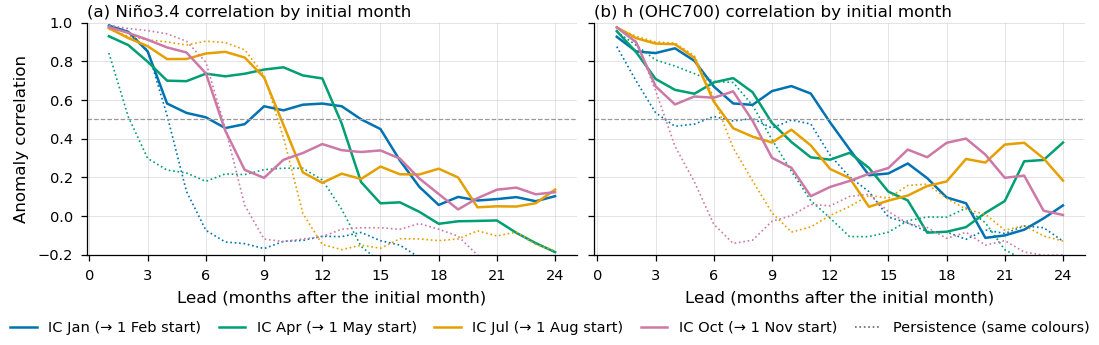

In [9]:
init_month = pd.DatetimeIndex(det["init"].values).month
MONTH_COLORS = {1: "#0072b2", 4: "#009e73", 7: "#e69f00", 10: "#cc79a7"}
fig, axes = plt.subplots(1, 2, figsize=(pf.WIDTH["double"], 2.3), sharey=True)
by_month = {}
for c, var in enumerate(SKILL_VARS):
    for start, ic in START_ICS.items():
        sel = np.flatnonzero(init_month == ic)
        sk = xc.skill(det[var].isel(init=sel), OBS_GRID[var].isel(init=sel))
        pe = xc.skill(xc.persistence(det, OBS_GRID)[var].isel(init=sel), OBS_GRID[var].isel(init=sel))
        by_month[(var, start)] = sk
        axes[c].plot(leads, sk["acc"].isel(lead=slice(1, None)), color=MONTH_COLORS[ic],
                     label=f"IC {xc.MONTH_NAMES[ic]} (→ 1 {xc.MONTH_NAMES[start]} start)")
        axes[c].plot(leads, pe["acc"].isel(lead=slice(1, None)), color=MONTH_COLORS[ic], ls=":", lw=0.8)
    axes[c].axhline(0.5, color="0.6", lw=0.6, ls="--")
    axes[c].set_ylim(-0.2, 1)
    axes[c].set_xticks(range(0, VALID["n_month"] + 1, 3))
    axes[c].set_xlabel("Lead (months after the initial month)")
    axes[c].grid(True)
    pf.panel_label(axes[c], c, f"{xc.short(var)} correlation by initial month")
axes[0].set_ylabel("Anomaly correlation")
handles, labels = axes[0].get_legend_handles_labels()
handles.append(plt.Line2D([], [], color="0.4", ls=":", lw=0.8))
labels.append("Persistence (same colours)")
pf.legend_below(fig, handles, labels, ncol=5)
pf.save(fig, NOTEBOOK, "xro", "oos_skill_by_initial_month")
plt.show()

## 6. Amplitude of the DJF peak

For every year Y of the validation period, the observed DJF (Y/Y+1) Niño3.4 against XRO's
out-of-sample forecast of the same season from the Jan, Apr, Jul and Oct initial months of Y (the
hindcast starts' initial months). The regression slope measures amplitude: a slope below 1 means
XRO forecasts are too weak, as expected of a damped linear-dominated model whose ensemble mean
regresses toward climatology. Bars are the stochastic 5-95% range; strong El Niños (observed
DJF ≥ `STRONG`) are labelled. This tests whether a weaker XRO forecast is itself evidence that
a dynamical model overshoots.

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7a_xro_validation/figures/fig_xro_djf_amplitude.pdf


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7a_xro_validation/figures/fig_xro_djf_amplitude.png


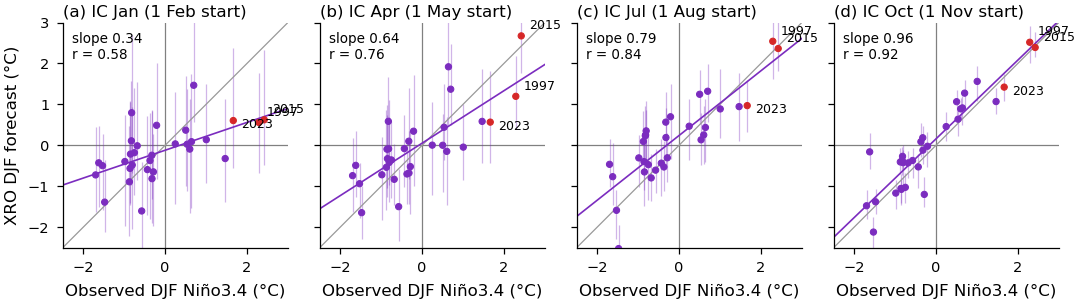

,initial month,slope,r,strong-event mean ratio forecast/observed,strong events inside 5-95%
start,,,,,
Feb,Jan,0.34,0.58,0.29,1/3
May,Apr,0.64,0.76,0.66,2/3
Aug,Jul,0.79,0.84,0.89,2/3
Nov,Oct,0.96,0.92,0.98,3/3


,start,Aug,Feb,May,Nov
year,obs_DJF,,,,
1997,2.291690,2.54,0.56,1.20,2.52
2015,2.424532,2.37,0.62,2.67,2.39
2023,1.666591,0.97,0.60,0.57,1.42


In [10]:
def djf_obs(Y):
    vals = [xc.obs_value(X, "Nino34", *ym) for ym in [(Y, 12), (Y + 1, 1), (Y + 1, 2)]]
    return float(np.mean(vals)) if np.all(np.isfinite(vals)) else np.nan


def djf_forecast(fc, Y, ic):
    """Forecast DJF (Y/Y+1) mean from initial month (Y, ic): leads 12-ic .. 14-ic."""
    i = np.flatnonzero(pd.DatetimeIndex(fc["init"].values) == pd.Timestamp(Y, ic, 1))
    if not i.size:
        return None
    return fc["Nino34"].isel(init=int(i[0])).sel(lead=[12 - ic, 13 - ic, 14 - ic]).mean("lead")


lo, hi = xc.XRO_SETUP["spread"]
amp_rows = []
for Y in range(VALID["years"][0], VALID["years"][1] + 1):
    o = djf_obs(Y)
    for start, ic in START_ICS.items():
        d = djf_forecast(det, Y, ic)
        s = djf_forecast(stoch, Y, ic)
        if d is None or not np.isfinite(o):
            continue
        amp_rows.append({"year": Y, "start": xc.MONTH_NAMES[start], "ic": xc.MONTH_NAMES[ic], "obs_DJF": o,
                         "xro_det": float(d), "xro_lo": float(s.quantile(lo / 100, "member")),
                         "xro_hi": float(s.quantile(hi / 100, "member"))})
amp = pd.DataFrame(amp_rows)

fig, axes = plt.subplots(1, 4, figsize=(pf.WIDTH["double"], 2.25), sharex=True, sharey=True)
amp_stats = []
for k, (ax, (start, ic)) in enumerate(zip(axes, START_ICS.items())):
    a = amp[amp["start"] == xc.MONTH_NAMES[start]]
    strong = a["obs_DJF"] >= STRONG
    ax.errorbar(a["obs_DJF"], a["xro_det"], yerr=[a["xro_det"] - a["xro_lo"], a["xro_hi"] - a["xro_det"]],
                fmt="none", ecolor=COLORS["XRO"], alpha=0.35, lw=0.6)
    ax.scatter(a["obs_DJF"], a["xro_det"], s=9, color=np.where(strong, "#d62728", COLORS["XRO"]), zorder=3)
    for _, r in a[strong].iterrows():
        ax.annotate(f"{r['year']}", (r["obs_DJF"], r["xro_det"]), xytext=(4, -2 + 7 * (r["year"] % 3 - 1)),
                    textcoords="offset points", fontsize=6, ha="left", va="center")
    slope, intercept = np.polyfit(a["obs_DJF"], a["xro_det"], 1)
    r = np.corrcoef(a["obs_DJF"], a["xro_det"])[0, 1]
    lim = np.array([-2.5, 3.0])
    ax.plot(lim, lim, color="0.6", lw=0.6)
    ax.plot(lim, intercept + slope * lim, color=COLORS["XRO"], lw=0.8)
    ax.text(0.04, 0.96, f"slope {slope:.2f}\nr = {r:.2f}", transform=ax.transAxes, va="top", fontsize=6.5)
    ax.set_xlim(*lim)
    ax.set_ylim(*lim)
    ax.set_aspect("equal")
    pf.zero_line(ax)
    pf.zero_line(ax, axis="x")
    ax.set_xlabel("Observed DJF Niño3.4 (°C)")
    pf.panel_label(ax, k, f"IC {xc.MONTH_NAMES[ic]} (1 {xc.MONTH_NAMES[start]} start)")
    amp_stats.append({"start": xc.MONTH_NAMES[start], "initial month": xc.MONTH_NAMES[ic], "slope": round(slope, 2),
                      "r": round(r, 2), "strong-event mean ratio forecast/observed":
                      round(float((a.loc[strong, "xro_det"] / a.loc[strong, "obs_DJF"]).mean()), 2),
                      "strong events inside 5-95%":
                      f"{int(((a.loc[strong, 'obs_DJF'] >= a.loc[strong, 'xro_lo']) & (a.loc[strong, 'obs_DJF'] <= a.loc[strong, 'xro_hi'])).sum())}/{int(strong.sum())}"})
axes[0].set_ylabel("XRO DJF forecast (°C)")
pf.save(fig, NOTEBOOK, "xro", "djf_amplitude")
plt.show()
amp.round(2).to_csv(OUTDIR / "XRO_oos_DJF_forecasts.csv", index=False)
display(pd.DataFrame(amp_stats).set_index("start"))
display(amp[amp["obs_DJF"] >= STRONG].pivot_table(index=["year", "obs_DJF"], columns="start", values="xro_det").round(2))

## 7. Calibration of the stochastic ensemble

A reliable ensemble has (a) spread (mean member standard deviation) close to the RMSE of its
ensemble mean, and (b) the observation inside the 5-95% range about 90% of the time. Spread below
RMSE means the red-noise ensemble is overconfident and its 5-95% bands in 7b-7c understate the
uncertainty.

A few red-noise members run away through XRO's nonlinear terms (about 0.1%, mostly beyond lead 11); members whose |Niño3.4| ever exceeds `xc.XRO_SETUP["diverge_threshold"]` (6 °C; observed maximum 2.6 °C) are excluded from all statistics. The count is printed below.

diverged stochastic members excluded: 26 of 18600


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7a_xro_validation/figures/fig_xro_stochastic_calibration.pdf


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7a_xro_validation/figures/fig_xro_stochastic_calibration.png


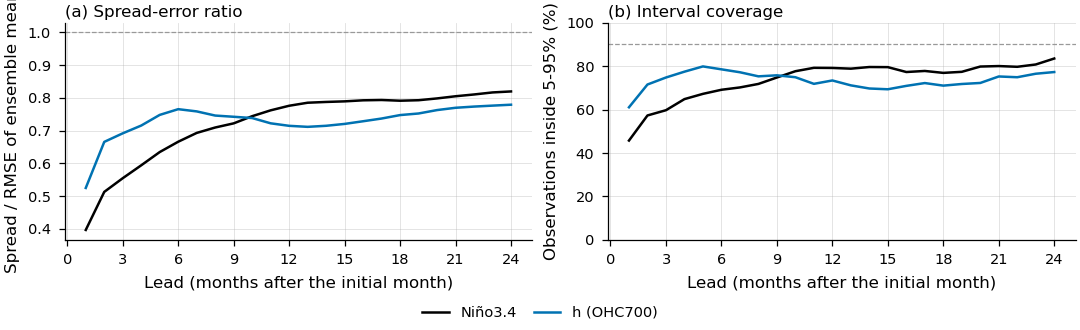

,variable,lead,spread/RMSE,% inside 5-95%
0,Niño3.4,3,0.55,59.7
1,Niño3.4,6,0.67,69.1
2,Niño3.4,12,0.78,79.1
3,h (OHC700),3,0.69,74.7
4,h (OHC700),6,0.77,78.5
5,h (OHC700),12,0.71,73.4


In [11]:
print(f"diverged stochastic members excluded: {stoch.attrs.get('diverged_members', 0)} of {stoch.sizes['init'] * stoch.sizes['member']}")
fig, axes = plt.subplots(1, 2, figsize=(pf.WIDTH["double"], 2.2))
calib_rows = []
for c, var in enumerate(SKILL_VARS):
    ens = stoch[var]
    o = OBS_GRID[var]
    ok = o.notnull()
    rmse = np.sqrt(((ens.mean("member") - o) ** 2).where(ok).mean("init"))
    spread = ens.std("member").where(ok).mean("init")
    inside = ((o >= ens.quantile(lo / 100, "member")) & (o <= ens.quantile(hi / 100, "member"))).where(ok).mean("init")
    axes[0].plot(leads, (spread / rmse).isel(lead=slice(1, None)), color=["k", "#0072b2"][c], label=xc.short(var))
    axes[1].plot(leads, 100 * inside.isel(lead=slice(1, None)), color=["k", "#0072b2"][c], label=xc.short(var))
    for L in (3, 6, 12):
        calib_rows.append({"variable": xc.short(var), "lead": L, "spread/RMSE": round(float(spread.sel(lead=L) / rmse.sel(lead=L)), 2),
                           f"% inside {lo}-{hi}%": round(100 * float(inside.sel(lead=L)), 1)})
axes[0].axhline(1.0, color="0.6", lw=0.6, ls="--")
axes[0].set_ylabel("Spread / RMSE of ensemble mean")
axes[1].axhline(hi - lo, color="0.6", lw=0.6, ls="--")
axes[1].set_ylabel(f"Observations inside {lo}-{hi}% (%)")
axes[1].set_ylim(0, 100)
for k, ax in enumerate(axes):
    ax.set_xlabel("Lead (months after the initial month)")
    ax.set_xticks(range(0, VALID["n_month"] + 1, 3))
    ax.grid(True)
pf.panel_label(axes[0], 0, "Spread-error ratio")
pf.panel_label(axes[1], 1, "Interval coverage")
pf.legend_below(fig, ax=axes[0], ncol=2)
pf.save(fig, NOTEBOOK, "xro", "stochastic_calibration")
plt.show()
calib = pd.DataFrame(calib_rows)
calib.to_csv(OUTDIR / "XRO_stochastic_calibration.csv", index=False)
display(calib)

## 8. Cross-validated calibration of the stochastic ensemble

Section 7 shows the red-noise ensemble is underdispersive. Here it is recalibrated statistically,
without changing the fitted XRO, its noise model or its ensemble mean: each member is moved away from
the ensemble mean by a lead-dependent factor α(L),

X$_m^{cal}$(L) = X̄(L) + α(L) [X$_m$(L) − X̄(L)].

For each past forecast, the "required inflation" is the factor by which its `lo`-`hi`% interval
(scaled about the mean, on the observation's side) would have to widen to just contain the
observation. α(L) is the 90th percentile of the required inflation, so the inflated interval
would have contained 90% of past observations; leads within ±`CAL["pool"]` are pooled.

**No future information.** A forecast issued in month t is calibrated only with past forecasts
whose *target* month precedes t (already verified when it is issued), not just forecasts started
earlier; forecasts with fewer than `CAL["min_samples"]` such cases stay uncalibrated. Scores are
computed over initial months from `CAL["first_test_year"]` on, where every forecast has a factor,
for the original and calibrated ensembles on the same cases.

Calibration succeeds if coverage moves to about 90% and spread/RMSE to about 1 without needlessly
wide intervals, and if CRPS (which rewards both reliability and sharpness) does not get worse.
Monthly calibration does not guarantee calibrated seasonal means, so the DJF Niño3.4 forecasts
from the four initial months are checked separately, with their own expanding-window factor.
A calibrated ensemble can still have biased amplitudes for strong events (section 6).

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7a_xro_validation/figures/fig_xro_stochastic_calibration_crossvalidated.pdf


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7a_xro_validation/figures/fig_xro_stochastic_calibration_crossvalidated.png


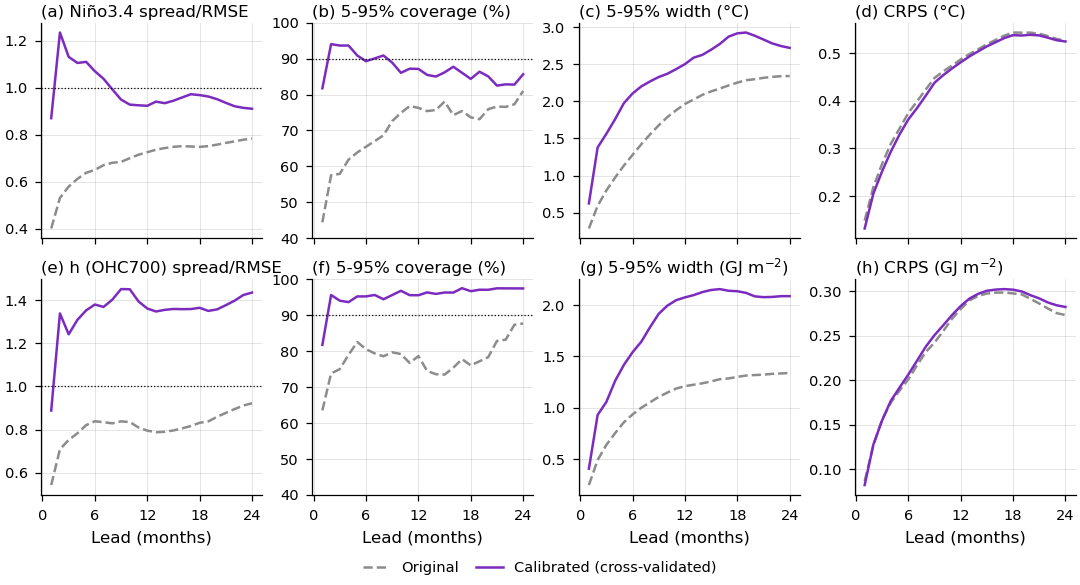

n  alpha (2026-01 issue)  spread/RMSE orig  coverage orig  \
variable   lead                                                                
Niño3.4    1     252                   2.08              0.40          44.44   
           3     252                   1.84              0.58          57.94   
           6     252                   1.57              0.65          65.48   
           12    249                   1.29              0.73          76.31   
           18    243                   1.33              0.75          73.66   
h (OHC700) 1     252                   1.52              0.54          63.49   
           3     252                   1.51              0.75          75.00   
           6     252                   1.47              0.84          80.56   
           12    248                   1.57              0.80          78.63   
           18    242                   1.41              0.83          76.03   

                 width orig  CRPS orig  spread/RMSE cali  coverage cali  \
variable   lead                                                           
Niño3.4    1           0.29       0.15              0.87          81.75   
           3           0.80       0.27              1.13          93.65   
           6           1.28       0.37              1.07          89.29   
           12          1.96       0.49              0.92          87.15   
           18          2.25       0.54              0.97          84.36   
h (OHC700) 1           0.25       0.09              0.89          81.75   
           3           0.64       0.16              1.24          94.05   
           6           0.94       0.20              1.38          95.24   
           12          1.21       0.28              1.36          95.56   
           18          1.30       0.30              1.37          96.69   

                 width cali  CRPS cali  
variable   lead                         
Niño3.4    1           0.63       0.13  
           3           1.56       0.25  
           6           2.11       0.36  
           12          2.50       0.48  
           18          2.92       0.54  
h (OHC700) 1           0.41       0.08  
           3           1.06       0.15  
           6           1.54       0.21  
           12          2.07       0.28  
           18          2.13       0.30

In [12]:
CAL = {"first_test_year": 2005, "djf_min_samples": 8} | {k: xc.CALIBRATION[k] for k in ("pool", "min_samples")}
NOMINAL = (hi - lo) / 100
test = pd.DatetimeIndex(stoch["init"].values).year >= CAL["first_test_year"]


def interval_stats(e, o, ok):
    mu = e.mean("member")
    ql = e.quantile(lo / 100, "member").drop_vars("quantile")
    qh = e.quantile(hi / 100, "member").drop_vars("quantile")
    return xr.Dataset({
        "spread/RMSE": e.std("member").where(ok).mean("init") / np.sqrt(((mu - o) ** 2).where(ok).mean("init")),
        "coverage": ((o >= ql) & (o <= qh)).where(ok).mean("init"),
        "width": (qh - ql).where(ok).mean("init"),
        "CRPS": xc.crps_ensemble(e, o).where(ok).mean("init"),
    })


CAL_RESULTS = {}
for var in SKILL_VARS:
    ens, o = stoch[var], OBS_GRID[var]
    r = xc.required_inflation(ens, o)
    alpha = xr.concat([xc.inflation_factors(r, t, pool=CAL["pool"], min_samples=CAL["min_samples"])[0]
                       for t in stoch["init"].values], dim="init").assign_coords(init=stoch["init"])
    e_t, o_t, a_t = ens.isel(init=test), o.isel(init=test), alpha.isel(init=test)
    ok = o_t.notnull() & a_t.notnull()
    CAL_RESULTS[var] = {"alpha": alpha, "original": interval_stats(e_t, o_t, ok),
                        "calibrated": interval_stats(xc.inflate(e_t, a_t), o_t, ok), "n": ok.sum("init")}

fig, axes = plt.subplots(2, 4, figsize=(pf.WIDTH["double"], 3.9), sharex=True)
for r_, var in enumerate(SKILL_VARS):
    for c, (key, ref, label) in enumerate([("spread/RMSE", 1.0, "spread/RMSE"), ("coverage", NOMINAL, f"{lo}-{hi}% coverage (%)"),
                                           ("width", None, f"{lo}-{hi}% width ({xc.UNITS[var]})"), ("CRPS", None, f"CRPS ({xc.UNITS[var]})")]):
        ax = axes[r_, c]
        for name, style in (("original", {"color": "0.55", "ls": "--", "label": "Original"}),
                            ("calibrated", {"color": COLORS["XRO"], "label": "Calibrated (cross-validated)"})):
            v = CAL_RESULTS[var][name][key].isel(lead=slice(1, None))
            ax.plot(leads, 100 * v if key == "coverage" else v, **style)
        if ref is not None:
            ax.axhline(100 * ref if key == "coverage" else ref, color="k", lw=0.6, ls=":")
        if key == "coverage":
            ax.set_ylim(40, 100)
        ax.set_xticks(range(0, VALID["n_month"] + 1, 6))
        ax.grid(True)
        if r_ == 1:
            ax.set_xlabel("Lead (months)")
        pf.panel_label(ax, 4 * r_ + c, f"{xc.short(var)} {label}" if c == 0 else label)
pf.legend_below(fig, ax=axes[0, 0], ncol=2)
pf.save(fig, NOTEBOOK, "xro", "stochastic_calibration_crossvalidated")
plt.show()

rows = []
for var in SKILL_VARS:
    for L in (1, 3, 6, 12, 18):
        row = {"variable": xc.short(var), "lead": L, "n": int(CAL_RESULTS[var]["n"].sel(lead=L)),
               "alpha (2026-01 issue)": round(float(xc.inflation_factors(xc.required_inflation(stoch[var], OBS_GRID[var]),
                                                                         "2026-01-01", pool=CAL["pool"])[0].sel(lead=L)), 2)}
        for name in ("original", "calibrated"):
            s = CAL_RESULTS[var][name].sel(lead=L)
            row |= {f"{k} {name[:4]}": round(float(s[k]) * (100 if k == "coverage" else 1), 2) for k in s.data_vars}
        rows.append(row)
cal_table = pd.DataFrame(rows)
cal_table.to_csv(OUTDIR / "XRO_stochastic_calibration_crossvalidated.csv", index=False)
display(cal_table.set_index(["variable", "lead"]))

In [13]:
# DJF Niño3.4 from the four initial months: expanding-window factor for the seasonal mean itself
def month_number(y, m):
    return y * 12 + m - 1


djf_rows, djf_detail = [], []
years = range(VALID["years"][0], VALID["years"][1] + 1)
for start, ic in START_ICS.items():
    ens = {Y: djf_forecast(stoch, Y, ic) for Y in years}
    obs_djf = {Y: djf_obs(Y) for Y in years}
    req = {}
    for Y in years:
        e, o = ens[Y], obs_djf[Y]
        if e is None or not np.isfinite(o):
            continue
        mu, ql, qh = float(e.mean()), float(e.quantile(lo / 100)), float(e.quantile(hi / 100))
        req[Y] = (o - mu) / max(qh - mu, 1e-8) if o >= mu else (mu - o) / max(mu - ql, 1e-8)
    for Y in years:
        if Y < CAL["first_test_year"] or Y not in req:
            continue
        issue = month_number(Y, ic)
        past = [req[Yp] for Yp in req if month_number(Yp + 1, 2) < issue]      # DJF Yp/Yp+1 verified before the issue
        if len(past) < CAL["djf_min_samples"]:
            continue
        a = float(np.quantile(past, NOMINAL))
        e, o = ens[Y], obs_djf[Y]
        mu = float(e.mean())
        ql, qh = float(e.quantile(lo / 100)), float(e.quantile(hi / 100))
        djf_detail.append({"start": xc.MONTH_NAMES[start], "year": Y, "obs": o, "alpha": a, "n_past": len(past),
                           "inside original": ql <= o <= qh, "inside calibrated": mu + a * (ql - mu) <= o <= mu + a * (qh - mu)})
    d = pd.DataFrame([r for r in djf_detail if r["start"] == xc.MONTH_NAMES[start]])
    djf_rows.append({"start": xc.MONTH_NAMES[start], "initial month": xc.MONTH_NAMES[ic], "test years": len(d),
                     "alpha (last)": round(d["alpha"].iloc[-1], 2),
                     "coverage original (%)": round(100 * d["inside original"].mean(), 1),
                     "coverage calibrated (%)": round(100 * d["inside calibrated"].mean(), 1),
                     "strong El Niños inside (orig / cal)":
                     f"{int(d.loc[d['obs'] >= STRONG, 'inside original'].sum())} / {int(d.loc[d['obs'] >= STRONG, 'inside calibrated'].sum())}"
                     f" of {int((d['obs'] >= STRONG).sum())}"})
djf_cal = pd.DataFrame(djf_rows).set_index("start")
djf_cal.to_csv(OUTDIR / "XRO_DJF_calibration_crossvalidated.csv")
pd.DataFrame(djf_detail).round(3).to_csv(OUTDIR / "XRO_DJF_calibration_crossvalidated_by_year.csv", index=False)
display(djf_cal)

# Archive the factors for the event starts (issue = XRO initial month); event lead = XRO lead - 1
arch = []
for year, event in xc.EVENTS.items():
    for init in event["init_months"]:
        issue = pd.Timestamp(*xc.add_months(year, init, -1), 1)
        for var in SKILL_VARS:
            a, n = xc.inflation_factors(xc.required_inflation(stoch[var], OBS_GRID[var]), issue,
                                        pool=CAL["pool"], min_samples=CAL["min_samples"])
            for L in a["lead"].values:
                arch.append({"event": event["label"], "start": f"{year}-{init:02d}-01", "issue (XRO initial month)": f"{issue:%Y-%m}",
                             "variable": var, "xro_lead": int(L), "event_lead": int(L) - 1, "alpha": float(a.sel(lead=L)),
                             "n_cases": int(n.sel(lead=L)), "verified_before": f"{issue:%Y-%m}",
                             "hindcast_years": f"{VALID['years'][0]}-{VALID['years'][1]}", "train_start": VALID["train_start"],
                             "detrend": CONTROL, "interval": f"{lo}-{hi}%", "pool": CAL["pool"], "min_samples": CAL["min_samples"],
                             "obs": f"{xc.OBS_SST} SST, EN4.2.2 OHC700"})
pd.DataFrame(arch).round(3).to_csv(OUTDIR / "XRO_inflation_factors_event_starts.csv", index=False)
print(OUTDIR / "XRO_inflation_factors_event_starts.csv")

,initial month,test years,alpha (last),coverage original (%),coverage calibrated (%),strong El Niños inside (orig / cal)
start,,,,,,
Feb,Jan,21,1.09,81.0,95.2,1 / 2 of 2
May,Apr,21,1.08,90.5,95.2,2 / 2 of 2
Aug,Jul,21,1.75,71.4,85.7,1 / 2 of 2
Nov,Oct,21,1.71,57.1,95.2,2 / 2 of 2


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7a_xro_validation/data/XRO_inflation_factors_event_starts.csv


## 9. Calibration objective and sampling uncertainty

Two refinements of section 8:

* **Objective.** Section 8 picks α(L) for 90% coverage. Here it is compared with α(L) minimizing
  the mean CRPS of the same past, already-verified forecasts (`xc.inflation_factors_crps`; α may be
  below 1). Coverage targets one interval; CRPS rewards reliability and sharpness over the whole
  distribution, so it can give narrower intervals where coverage-based inflation overshoots (*h*).
* **Uncertainty.** Monthly forecasts from consecutive initial months overlap, so cases are not
  independent: coverage and the CRPS change are bootstrapped by resampling whole initialization
  years (`BOOT["n"]` resamples, 95% intervals). The DJF forecasts (one per year and initial month,
  21 test years) get Wilson 95% intervals for coverage and the same year bootstrap for the CRPS change.

A method is preferred only if it is better on these held-out cases. DJF factors are estimated for the
DJF mean itself (not from monthly factors) and archived separately; 7b and 7c apply those to their
DJF ranges and the monthly factors only to monthly time series.

**Applied in 7b/7c** (`xc.CALIBRATION["method"]`): Niño3.4 with the 90%-coverage objective, *h* with the
minimum-CRPS objective (the coverage objective over-widens *h*; the CRPS objective brings it to about 90%
coverage at no CRPS cost). The factors actually applied to the event starts are archived.

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7a_xro_validation/figures/fig_xro_calibration_objective_comparison.pdf


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7a_xro_validation/figures/fig_xro_calibration_objective_comparison.png


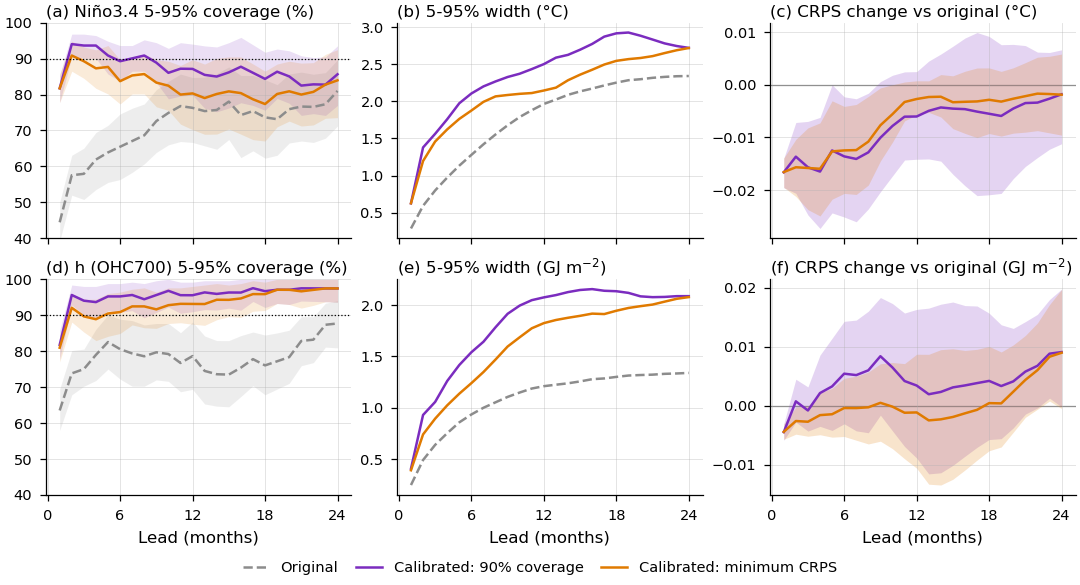

variable                                    Niño3.4                           \
lead                                             3                        6    
coverage original (%)             57.9 [50.8, 65.1]        65.5 [56.3, 74.6]   
width original                                  0.8                     1.28   
coverage coverage (%)             93.7 [90.1, 96.8]        89.3 [83.7, 93.7]   
width coverage                                 1.56                     2.11   
coverage crps (%)                 89.3 [84.5, 93.3]        83.7 [77.4, 89.7]   
width crps                                     1.46                     1.88   
ΔCRPS coverage              -0.016 [-0.025, -0.007]  -0.014 [-0.025, -0.002]   
ΔCRPS crps                  -0.016 [-0.024, -0.008]  -0.012 [-0.021, -0.004]   
alpha crps (2026-01 issue)                     1.75                     1.45   

variable                                                         h (OHC700)  \
lead                                            12                       3    
coverage original (%)            76.3 [66.7, 84.7]        75.0 [70.2, 80.6]   
width original                                1.96                     0.64   
coverage coverage (%)            87.1 [79.8, 94.0]        94.0 [90.1, 98.0]   
width coverage                                 2.5                     1.06   
coverage crps (%)                80.3 [70.2, 89.7]        89.7 [85.3, 94.4]   
width crps                                    2.15                     0.89   
ΔCRPS coverage              -0.006 [-0.014, 0.002]   -0.001 [-0.004, 0.003]   
ΔCRPS crps                  -0.003 [-0.006, 0.001]  -0.003 [-0.005, -0.000]   
alpha crps (2026-01 issue)                    1.15                     1.35   

variable                                                                    
lead                                            6                       12  
coverage original (%)            80.6 [72.2, 88.9]       78.6 [69.4, 88.1]  
width original                                0.94                    1.21  
coverage coverage (%)            95.2 [90.9, 98.8]       95.6 [91.0, 99.2]  
width coverage                                1.54                    2.07  
coverage crps (%)                90.9 [84.9, 96.4]       93.1 [87.5, 98.0]  
width crps                                    1.24                    1.82  
ΔCRPS coverage               0.005 [-0.003, 0.014]   0.003 [-0.009, 0.016]  
ΔCRPS crps                  -0.000 [-0.005, 0.005]  -0.001 [-0.011, 0.009]  
alpha crps (2026-01 issue)                    1.25                    1.35

In [14]:
BOOT = {"n": 1000, "seed": 7}
METHODS = ("original", "coverage", "crps")
METHOD_STYLE = {"original": {"color": "0.55", "ls": "--", "label": "Original"},
                "coverage": {"color": COLORS["XRO"], "label": "Calibrated: 90% coverage"},
                "crps": {"color": "#e07a00", "label": "Calibrated: minimum CRPS"}}
rng = np.random.default_rng(BOOT["seed"])
test_years = pd.DatetimeIndex(stoch["init"].values[test]).year.values
year_groups = [np.flatnonzero(test_years == y) for y in np.unique(test_years)]
boot_idx = [np.concatenate([year_groups[g] for g in rng.integers(0, len(year_groups), len(year_groups))])
            for _ in range(BOOT["n"])]


def boot_mean(a):
    """Mean over init and its year-block bootstrap 95% interval; a: (init, lead) array with NaN."""
    a = np.asarray(a, float)
    with np.errstate(all="ignore"):
        bs = np.array([np.nanmean(a[idx], axis=0) for idx in boot_idx])
    return np.nanmean(a, axis=0), np.nanpercentile(bs, [2.5, 97.5], axis=0)


REFINE = {}
for var in SKILL_VARS:
    ens, o = stoch[var], OBS_GRID[var]
    C = xc.crps_scaled(ens, o)
    alphas = {"coverage": CAL_RESULTS[var]["alpha"],
              "crps": xr.concat([xc.inflation_factors_crps(C, t, pool=CAL["pool"], min_samples=CAL["min_samples"])[0]
                                 for t in stoch["init"].values], dim="init").assign_coords(init=stoch["init"])}
    e_t, o_t = ens.isel(init=test), o.isel(init=test)
    ok = o_t.notnull() & alphas["coverage"].isel(init=test).notnull() & alphas["crps"].isel(init=test).notnull()
    res = {"alpha": alphas}
    for name in METHODS:
        e = e_t if name == "original" else xc.inflate(e_t, alphas[name].isel(init=test))
        ql = e.quantile(lo / 100, "member").drop_vars("quantile")
        qh = e.quantile(hi / 100, "member").drop_vars("quantile")
        inside = ((o_t >= ql) & (o_t <= qh)).astype(float).where(ok)
        res[name] = {"coverage": boot_mean(inside.values), "width": boot_mean((qh - ql).where(ok).values),
                     "crps": xc.crps_ensemble(e, o_t).where(ok)}
    for name in ("coverage", "crps"):
        res[name]["dcrps"] = boot_mean((res[name]["crps"] - res["original"]["crps"]).values)
    REFINE[var] = res

L = stoch["lead"].values
fig, axes = plt.subplots(2, 3, figsize=(pf.WIDTH["double"], 3.9), sharex=True)
for r_, var in enumerate(SKILL_VARS):
    ax = axes[r_, 0]
    for name in METHODS:
        m, ci = REFINE[var][name]["coverage"]
        ax.fill_between(L[1:], 100 * ci[0][1:], 100 * ci[1][1:], color=METHOD_STYLE[name]["color"], alpha=0.15, lw=0)
        ax.plot(L[1:], 100 * m[1:], **METHOD_STYLE[name])
    ax.axhline(100 * NOMINAL, color="k", lw=0.6, ls=":")
    ax.set_ylim(40, 100)
    pf.panel_label(ax, 3 * r_, f"{xc.short(var)} {lo}-{hi}% coverage (%)")
    ax = axes[r_, 1]
    for name in METHODS:
        ax.plot(L[1:], REFINE[var][name]["width"][0][1:], **METHOD_STYLE[name])
    pf.panel_label(ax, 3 * r_ + 1, f"{lo}-{hi}% width ({xc.UNITS[var]})")
    ax = axes[r_, 2]
    for name in ("coverage", "crps"):
        m, ci = REFINE[var][name]["dcrps"]
        ax.fill_between(L[1:], ci[0][1:], ci[1][1:], color=METHOD_STYLE[name]["color"], alpha=0.2, lw=0)
        ax.plot(L[1:], m[1:], **METHOD_STYLE[name])
    pf.zero_line(ax)
    pf.panel_label(ax, 3 * r_ + 2, f"CRPS change vs original ({xc.UNITS[var]})")
for ax in axes.flat:
    ax.set_xticks(range(0, VALID["n_month"] + 1, 6))
    ax.grid(True)
for ax in axes[1]:
    ax.set_xlabel("Lead (months)")
pf.legend_below(fig, ax=axes[0, 0], ncol=3)
pf.save(fig, NOTEBOOK, "xro", "calibration_objective_comparison")
plt.show()


def fmt(m, ci, scale=1, nd=1):
    return f"{scale * m:.{nd}f} [{scale * ci[0]:.{nd}f}, {scale * ci[1]:.{nd}f}]"


rows = []
for var in SKILL_VARS:
    for lead in (3, 6, 12):
        row = {"variable": xc.short(var), "lead": lead}
        for name in METHODS:
            m, ci = REFINE[var][name]["coverage"]
            row[f"coverage {name} (%)"] = fmt(m[lead], ci[:, lead], 100)
            row[f"width {name}"] = round(float(REFINE[var][name]["width"][0][lead]), 2)
        for name in ("coverage", "crps"):
            m, ci = REFINE[var][name]["dcrps"]
            row[f"ΔCRPS {name}"] = fmt(m[lead], ci[:, lead], nd=3)
        row["alpha crps (2026-01 issue)"] = float(REFINE[var]["alpha"]["crps"].sel(init="2025-12-01", lead=lead)) \
            if np.datetime64("2025-12-01") in stoch["init"].values else np.nan
        rows.append(row)
objective_table = pd.DataFrame(rows).set_index(["variable", "lead"])
objective_table.to_csv(OUTDIR / "XRO_calibration_objective_comparison.csv")
display(objective_table.T)

In [15]:
# DJF Niño3.4: DJF-specific factors, both objectives, Wilson intervals for coverage
def wilson(k, n, z=1.96):
    if n == 0:
        return np.nan, np.nan
    p = k / n
    den = 1 + z ** 2 / n
    c = (p + z ** 2 / (2 * n)) / den
    h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / den
    return c - h, c + h


djf_rows, djf_cases_out = [], []
for start, ic in START_ICS.items():
    ens, obs_d, verified = xc.djf_cases(stoch, X, ic)
    years_i = pd.DatetimeIndex(ens["init"].values).year.values
    recs = []
    for j in np.flatnonzero((years_i >= CAL["first_test_year"]) & np.isfinite(obs_d.values)):
        issue = pd.Timestamp(ens["init"].values[j])
        e, o = ens.isel(init=j), float(obs_d[j])
        rec = {"start": xc.MONTH_NAMES[start], "year": int(years_i[j]), "obs": o}
        for name in METHODS:
            a = 1.0 if name == "original" else xc.djf_factor(ens, obs_d, verified, issue, method=name,
                                                              min_samples=CAL["djf_min_samples"])[0]
            if not np.isfinite(a):
                rec = None
                break
            ee = e.mean() + a * (e - e.mean())
            ql, qh = float(ee.quantile(lo / 100)), float(ee.quantile(hi / 100))
            rec |= {f"alpha {name}": a, f"inside {name}": ql <= o <= qh, f"width {name}": qh - ql,
                    f"crps {name}": float(xc.crps_ensemble(ee.expand_dims(init=[0]), xr.DataArray([o], dims="init"))[0])}
        if rec is not None:
            recs.append(rec)
    d = pd.DataFrame(recs)
    djf_cases_out.append(d)
    row = {"start": xc.MONTH_NAMES[start], "n years": len(d)}
    for name in METHODS:
        k_in = int(d[f"inside {name}"].sum())
        lo_ci, hi_ci = wilson(k_in, len(d))
        row[f"coverage {name} (%)"] = f"{100 * k_in / len(d):.0f} [{100 * lo_ci:.0f}, {100 * hi_ci:.0f}]"
        row[f"width {name}"] = round(d[f"width {name}"].mean(), 2)
    for name in ("coverage", "crps"):
        diff = (d[f"crps {name}"] - d["crps original"]).values
        bs = [np.mean(diff[rng.integers(0, len(diff), len(diff))]) for _ in range(BOOT["n"])]
        row[f"ΔCRPS {name}"] = f"{diff.mean():+.3f} [{np.percentile(bs, 2.5):+.3f}, {np.percentile(bs, 97.5):+.3f}]"
    djf_rows.append(row)
djf_objective = pd.DataFrame(djf_rows).set_index("start")
djf_objective.to_csv(OUTDIR / "XRO_DJF_calibration_objective_comparison.csv")
pd.concat(djf_cases_out).round(3).to_csv(OUTDIR / "XRO_DJF_calibration_objective_by_year.csv", index=False)
display(djf_objective.T)

# Archive the DJF-specific factors for the event starts (applied to DJF ranges in 7b/7c)
arch, applied = [], []
for year, event in xc.EVENTS.items():
    for init in event["init_months"]:
        issue = pd.Timestamp(*xc.add_months(year, init, -1), 1)
        for var in xc.CALIBRATION["vars"]:
            for lead, a in xc.event_inflation(X, year, init, var).to_series().items():
                applied.append({"event": event["label"], "start": f"{year}-{init:02d}-01", "variable": var,
                                "method": xc.calibration_method(var), "event_lead": int(lead), "alpha": round(float(a), 3),
                                "verified_before": f"{issue:%Y-%m}"})
            for name in ("coverage", "crps"):
                a, n = xc.event_djf_inflation(X, year, init, var, method=name)
                arch.append({"event": event["label"], "start": f"{year}-{init:02d}-01", "issue (XRO initial month)": f"{issue:%Y-%m}",
                             "variable": var, "season": event["peak_season"]["label"], "method": name,
                             "applied in 7b/7c": name == xc.calibration_method(var), "alpha": round(a, 3), "n_past_seasons": n,
                             "verified_before": f"{issue:%Y-%m}", "hindcast_years": f"{VALID['years'][0]}-{VALID['years'][1]}",
                             "detrend": CONTROL, "interval": f"{lo}-{hi}%",
                             "obs": f"{xc.OBS_SST} SST" if var == "Nino34" else "EN4.2.2 OHC700"})
djf_arch = pd.DataFrame(arch)
djf_arch.to_csv(OUTDIR / "XRO_DJF_inflation_factors_event_starts.csv", index=False)
pd.DataFrame(applied).to_csv(OUTDIR / "XRO_applied_monthly_inflation_factors_event_starts.csv", index=False)
print("applied objectives:", {v: xc.calibration_method(v) for v in xc.CALIBRATION["vars"]})
display(djf_arch.pivot_table(index=["event", "start"], columns=["variable", "method"], values="alpha"))

start,Feb,May,Aug,Nov
n years,21,21,21,21
coverage original (%),"81 [60, 92]","90 [71, 97]","71 [50, 86]","57 [37, 76]"
width original,2.57,2.03,1.34,0.69
coverage coverage (%),"95 [77, 99]","95 [77, 99]","86 [65, 95]","95 [77, 99]"
width coverage,2.88,2.23,2.45,1.19
coverage crps (%),"81 [60, 92]","95 [77, 99]","81 [60, 92]","95 [77, 99]"
width crps,2.71,2.4,2.37,1.4
ΔCRPS coverage,"-0.004 [-0.014, +0.006]","-0.002 [-0.007, +0.003]","-0.006 [-0.046, +0.027]","-0.019 [-0.034, -0.004]"
ΔCRPS crps,"+0.003 [-0.004, +0.011]","+0.001 [-0.009, +0.010]","-0.007 [-0.040, +0.024]","-0.017 [-0.038, +0.004]"


applied objectives: {'Nino34': 'coverage', 'WWV': 'crps'}


variable                     Nino34            WWV      
method                     coverage  crps coverage  crps
event           start                                   
2015/16 El Niño 2015-02-01    1.133  1.05    1.156  1.20
                2015-05-01    1.079  1.20    1.261  1.40
                2015-08-01    1.882  1.80    1.526  1.35
                2015-11-01    1.708  2.05    1.669  1.55
2026/27 El Niño 2026-02-01    1.088  1.10    0.993  1.05
                2026-05-01    1.074  1.15    1.248  1.20
                2026-08-01    1.741  1.60    1.514  1.30

## 10. Verification of the out-of-sample procedure

Executable checks of `xc.rolling_hindcasts` and the calibration filters (computed without the cache):

1. **No future observations.** Every observation after year Y is replaced by noise; forecasts started
   in Y must not change. Control: shifting the year-Y initial states must change them.
2. **Training window.** The trend and the fitted operator for Y do not change when data after Y−1 change.
3. **Calibration filter.** Factors for an issue month do not change when every validation case
   verified at or after that month is replaced by an extreme value.
4. **Alignment.** Forecast lead 0 (trend added back) equals the observed initial month.
5. **Cache.** The cached hindcasts equal a fresh computation.

In [16]:
%%time
checks, rng_a = [], np.random.default_rng(0)
for Y in (1995, 2010, 2024):
    Xs = X.copy(deep=True)
    later = Xs["time"].dt.year.values > Y
    for v in Xs.data_vars:
        Xs[v].values[later] = rng_a.normal(0, 5, later.sum())
    a, _ = xc.rolling_hindcasts(X, (Y, Y), VALID["train_start"], VALID["n_month"], use_cache=False)
    b, _ = xc.rolling_hindcasts(Xs, (Y, Y), VALID["train_start"], VALID["n_month"], use_cache=False)
    diff = float(abs(a - b).to_array().max())
    checks.append({"check": f"1. obs after {Y} scrambled: max forecast change", "value": diff, "pass": diff == 0})
Xs = X.copy(deep=True)
m = Xs["time"].dt.year.values == 2015
for v in Xs.data_vars:
    Xs[v].values[m] += 0.5
a, _ = xc.rolling_hindcasts(X, (2015, 2015), VALID["train_start"], VALID["n_month"], use_cache=False)
b, _ = xc.rolling_hindcasts(Xs, (2015, 2015), VALID["train_start"], VALID["n_month"], use_cache=False)
diff = float(abs(a - b).to_array().max())
checks.append({"check": "1. control: 2015 initial states +0.5, forecast change", "value": diff, "pass": diff > 0})

xa = xc.fit_xro(X, (1981, 2014))
xb = xc.fit_xro(X.where(X["time"].dt.year < 2015, 99.0), (1981, 2014))
diff = max(float(np.max(abs(xa["trend"][v] - xb["trend"][v]))) for v in xc.XRO_VARS) + float(abs(xa["fit"]["Lac"] - xb["fit"]["Lac"]).max())
checks.append({"check": "2. data after 2014 replaced: trend + operator change", "value": diff, "pass": diff == 0})

r = xc.required_inflation(stoch["Nino34"], OBS_GRID["Nino34"])
issue = pd.Timestamp("2015-04-01")
target = (pd.DatetimeIndex(r["init"].values).year.values * 12 + pd.DatetimeIndex(r["init"].values).month.values - 1)[:, None] + r["lead"].values[None, :]
r_bad = r.where(target < issue.year * 12 + issue.month - 1, 1e6)
diff = float(abs(xc.inflation_factors(r, issue)[0] - xc.inflation_factors(r_bad, issue)[0]).max())
checks.append({"check": "3. cases verified on/after the issue month set to 1e6: factor change", "value": diff, "pass": diff == 0})

diff = float(abs(det.isel(lead=0) - OBS_GRID.isel(lead=0)).to_array().max())
checks.append({"check": "4. |forecast lead 0 - observed initial month|", "value": diff, "pass": diff < 1e-10})

fresh, _ = xc.rolling_hindcasts(X, VALID["years"], VALID["train_start"], VALID["n_month"], use_cache=False)
diff = float(abs(det - fresh).to_array().max())
checks.append({"check": "5. cached - fresh deterministic hindcasts", "value": diff, "pass": diff < 1e-10})
audit = pd.DataFrame(checks)
audit.to_csv(OUTDIR / "XRO_out_of_sample_audit.csv", index=False)
display(audit)
assert audit["pass"].all(), "out-of-sample audit failed"

,check,value,pass
0,1. obs after 1995 scrambled: max forecast change,0.000000e+00,True
1,1. obs after 2010 scrambled: max forecast change,0.000000e+00,True
2,1. obs after 2024 scrambled: max forecast change,0.000000e+00,True
3,"1. control: 2015 initial states +0.5, forecast...",1.922610e+00,True
4,2. data after 2014 replaced: trend + operator ...,0.000000e+00,True
5,3. cases verified on/after the issue month set...,0.000000e+00,True
6,4. |forecast lead 0 - observed initial month|,2.220446e-16,True
7,5. cached - fresh deterministic hindcasts,0.000000e+00,True


CPU times: user 33 s, sys: 531 ms, total: 33.5 s
Wall time: 33.9 s


## Summary for the later notebooks

Read the tables above against these questions before using XRO as the benchmark in 7b-7d:

* **Regime (section 2-3):** damped oscillator with a period of a few years, winter phase-locking,
  *h* leading *T* by several months, positive Niño3.4 skewness.
* **Skill (section 4-5):** correlation clearly above persistence beyond about 3 months; the Jan
  initial month (Feb starts) is the weakest.
* **Amplitude (section 6):** the DJF regression slope and the strong-event ratio say how much weaker
  than observed a skilful XRO forecast typically is. An E3SM-minus-XRO difference of that size or
  smaller is not evidence that E3SM overshoots.
* **Uncertainty (sections 7-8):** the raw red-noise ensemble is underdispersive; use the cross-validated
  inflation factors (archived for the event starts) when quoting XRO uncertainty, and check the DJF table.
* **Detrending (section 4):** if linear and quadratic *h* trends give clearly different skill, the
  event forecasts in 7b should be shown for both.